# ms-10: When do independent cells mispredict a supercell?

In [1]:
from pathlib import Path
import sys, json, hashlib, platform
from dataclasses import asdict, replace
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
ROOT = Path.cwd()
if not (ROOT/'simulations').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT/'simulations'))
from design_studies import (Design, order_metrics, spectral_sweep, bandwidth,
                           local_prediction, optimize_widths, grcwa_check)
from unit_cell_te import Cell, solve_cell, sample_ey
plt.rcParams.update({'figure.dpi': 125, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})
OUT = ROOT/'data/design-studies'; OUT.mkdir(parents=True, exist_ok=True)
def metadata(design):
    import scipy
    return dict(parameters=asdict(design), units='um, degrees; incident-normalized power',
      conventions='exp(-i omega t), TE Ey, r at z=0, t at z=height',
      sources={name:hashlib.sha256((ROOT/'simulations'/name).read_text(encoding='utf-8').encode()).hexdigest()
               for name in ['design_studies.py','unit_cell_te.py','metasurface_synthesis.py']},
      environment={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__})
def geometry(ax, design, title):
    L=len(design.widths_um)*design.pitch_um; h=design.height_um
    ax.add_patch(Rectangle((0,h),L,.32,fc='#c3ddeb'))
    for j,w in enumerate(design.widths_um):
        ax.add_patch(Rectangle(((j+.5)*design.pitch_um-w/2,0),w,h,fc='#167b9b',ec='white'))
        ax.text((j+.5)*design.pitch_um,-.07,str(j+1),ha='center',fontsize=9)
    ax.axvline(0,c='#9866aa',ls='--');ax.axvline(L,c='#9866aa',ls='--')
    ax.set(xlim=(-.1,L+.1),ylim=(h+.32,-.4),xlabel='x (um)',ylabel='z (um)',title=title)
    ax.text(.05,.04,'TE: E along y; k along +z',transform=ax.transAxes,fontsize=8)
    ax.text(.05,.13,'Repeated in x; invariant in y',transform=ax.transAxes,fontsize=8)


Each local coefficient comes from a ridge surrounded by **identical copies of itself**. We then place six different ridges next to one another and solve the full periodic supercell. Their pitch, height, indices, illumination and two phase planes are identical between models. The discrepancy includes changed neighbors **and** the staircase approximation to the exit field; it is not a uniquely isolated coupling constant. See the [lab](../labs/10-coupling-lab.md).

In [2]:
design=Design(); contrasts=np.linspace(0,1,5)
M_cell, M_full, M_check=24,144,192
orders=np.arange(-5,6); mean=np.mean(design.widths_um)
cases=[]
for alpha in contrasts:
    widths=mean+alpha*(np.array(design.widths_um)-mean)
    current=replace(design,widths_um=tuple(widths)); full=current.solve(M_full); check=current.solve(M_check)
    local=local_prediction(current,orders,M_cell); local_check=local_prediction(current,orders,32)
    ix=orders+M_full; iy=orders+M_check
    delta=max(abs(full['T'][ix]-check['T'][iy]).max(),abs(full['R'][ix]-check['R'][iy]).max())
    local_delta=max(abs(local['T']-local_check['T']).max(),abs(local['R']-local_check['R']).max())
    assert delta<1e-4 and local_delta<1e-4
    cases.append(dict(contrast=float(alpha),widths_um=widths.tolist(),orders=orders.tolist(),
        full_T=check['T'][iy].tolist(),full_R=check['R'][iy].tolist(),
        local_T=local['T'].tolist(),local_R=local['R'].tolist(),
        full_balance_error=check['balance_error'],local_power_sum=float(local['R'].sum()+local['T'].sum()),
        harmonic_power_change=float(delta),local_harmonic_change=float(local_delta)))
# Identical-ridge embedding: matched physical Fourier cutoffs, M_super=6*M_cell.
uniform=replace(design,widths_um=(float(mean),)*6)
p=asdict(uniform);p.pop('widths_um');p['period_um']=p.pop('pitch_um')
a=solve_cell(Cell(width_um=float(mean),**p),24); b=uniform.solve(144)
embedding_error=max(abs(a['t'][24]-b['t'][144]),abs(a['r'][24]-b['r'][144]))
forbidden=(b['orders']%6)!=0
forbidden_amplitude=max(abs(b['t'][forbidden]).max(),abs(b['r'][forbidden]).max())
assert embedding_error<1e-10 and forbidden_amplitude<1e-10
print('Uniform embedding complex error:',embedding_error)
for c in cases:
    i=list(orders).index(1)
    print('contrast',c['contrast'],'local/full T+1',c['local_T'][i],c['full_T'][i],
          'local R+T',c['local_power_sum'])


Uniform embedding complex error: 5.689763699370293e-13
contrast 0.0 local/full T+1 7.338369388018298e-33 1.6499315079568533e-30 local R+T 1.0
contrast 0.25 local/full T+1 0.06163240531603241 0.0820703402831775 local R+T 0.9660180539068518
contrast 0.5 local/full T+1 0.2924996988766575 0.3447767348386402 local R+T 0.9037764523675431
contrast 0.75 local/full T+1 0.6237473148294989 0.6885164988095138 local R+T 0.8745858937225337
contrast 1.0 local/full T+1 0.8027335697727512 0.8553551432167072 local R+T 0.882249204847863


At contrast α=0, every width equals the mean: this is an exact identical-neighbor control. At α=1, the original Chapter 5 geometry is recovered. Do not force the approximate local R+T to one. A lossless full-wave solve conserves flux, while the stitched field does not enforce boundary continuity. Neither small flux error nor the uniform control alone validates a nonuniform design.

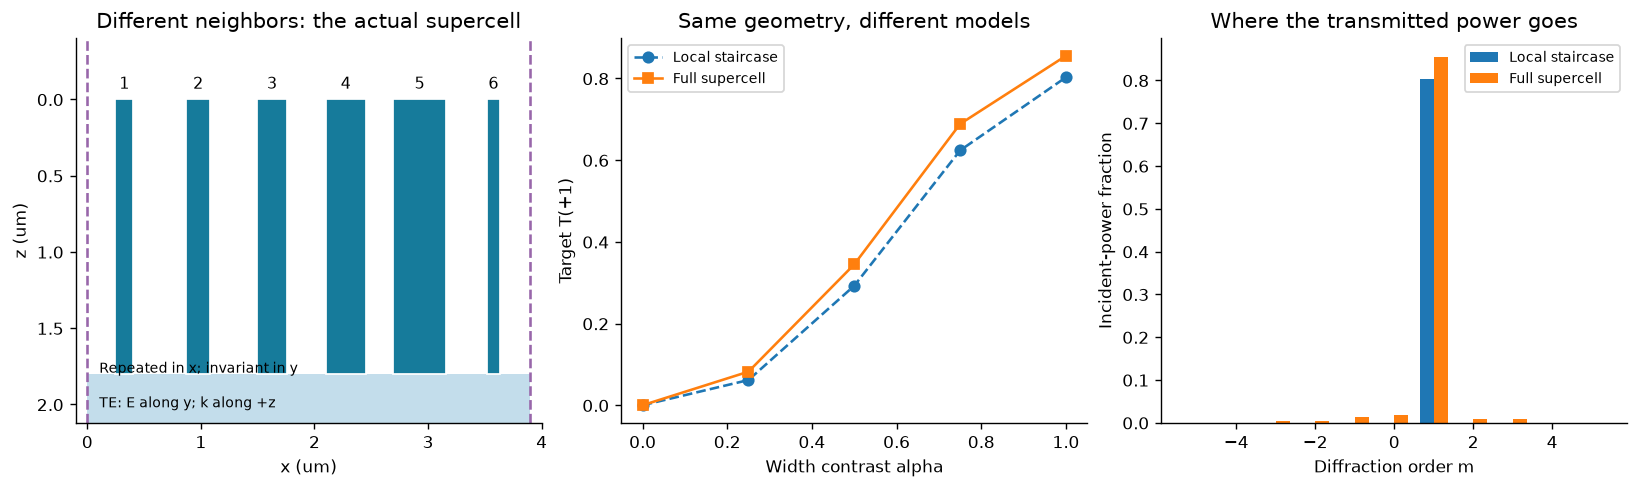

In [3]:
fig,ax=plt.subplots(1,3,figsize=(13,3.8),layout='constrained')
geometry(ax[0],design,'Different neighbors: the actual supercell')
i=list(orders).index(1)
ax[1].plot(contrasts,[c['local_T'][i] for c in cases],'o--',label='Local staircase')
ax[1].plot(contrasts,[c['full_T'][i] for c in cases],'s-',label='Full supercell')
ax[1].set(xlabel='Width contrast alpha',ylabel='Target T(+1)',title='Same geometry, different models');ax[1].legend(fontsize=8)
c=cases[-1];ax[2].bar(orders-.18,c['local_T'],width=.36,label='Local staircase')
ax[2].bar(orders+.18,c['full_T'],width=.36,label='Full supercell')
ax[2].set(xlabel='Diffraction order m',ylabel='Incident-power fraction',title='Where the transmitted power goes');ax[2].legend(fontsize=8)
plt.show()


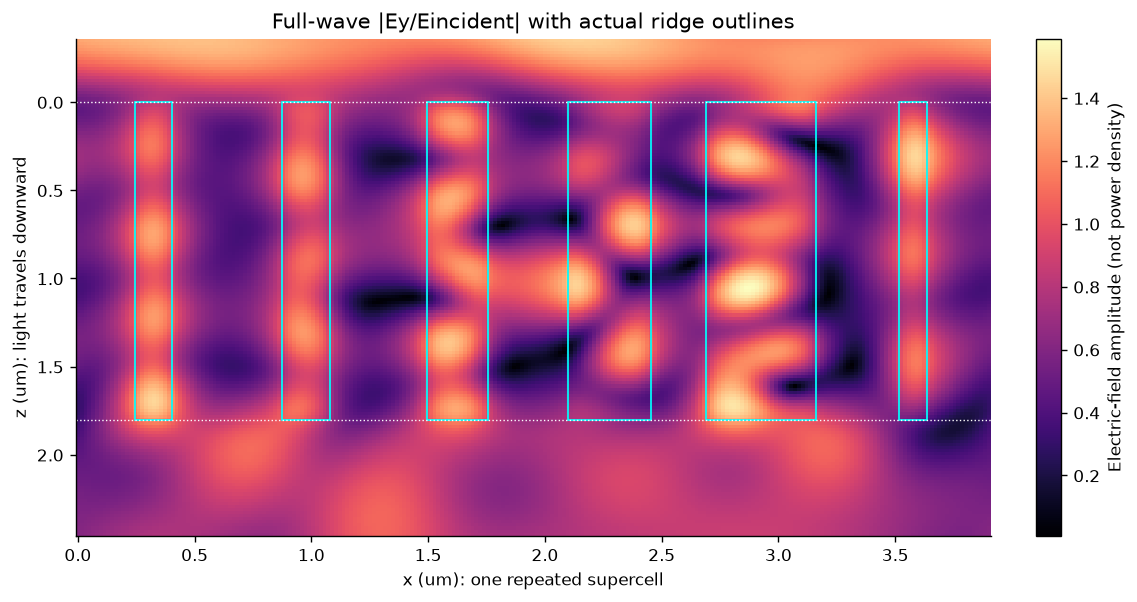

9329

In [4]:
full=design.solve(M_check)
cell=Cell(period_um=len(design.widths_um)*design.pitch_um,width_um=design.widths_um[0],
          height_um=design.height_um,wavelength_um=design.wavelength_um,n_ridge=design.n_ridge,
          n_gap=design.n_gap,n_incident=design.n_incident,n_substrate=design.n_substrate)
x=np.linspace(0,cell.period_um,241);z=np.linspace(-.35,design.height_um+.65,161)
field=sample_ey(cell,full,x,z)
fig,ax=plt.subplots(figsize=(9,4.7),layout='constrained')
pic=ax.pcolormesh(x,z,abs(field),shading='auto',cmap='magma')
for j,w in enumerate(design.widths_um):
    ax.add_patch(Rectangle(((j+.5)*design.pitch_um-w/2,0),w,design.height_um,fc='none',ec='cyan',lw=1))
ax.axhline(0,c='white',ls=':',lw=.8);ax.axhline(design.height_um,c='white',ls=':',lw=.8)
ax.invert_yaxis();ax.set(xlabel='x (um): one repeated supercell',ylabel='z (um): light travels downward',
    title='Full-wave |Ey/Eincident| with actual ridge outlines')
fig.colorbar(pic,ax=ax,label='Electric-field amplitude (not power density)');plt.show()
report=dict(metadata=metadata(design),cases=cases,half_orders=[M_full,M_check],
    local_half_orders=[M_cell,32],uniform_embedding_error=float(embedding_error),
    forbidden_amplitude=float(forbidden_amplitude))
(OUT/'coupling.json').write_text(json.dumps(report,indent=2)+'\n')


**Submit:** compare every open reflected/transmitted order, convergence changes, actual ridge outlines and both phase planes. Explain why α is width contrast, not an independently controlled physical coupling strength. Extension: vary pitch or neighbor ordering while keeping other physical inputs fixed, then rerun convergence. FEM/FDTD and finite arrays are separate unexecuted extensions.